<a href="https://colab.research.google.com/github/CarlosMDSN/ml-campus_data_project-python/blob/main/CampusDatasetProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Campus Database Project


## Data Preparation

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
import pandas as pd

Load the Dataset

In [19]:
df= pd.read_csv(
    '/content/drive/MyDrive/Colab Notebooks/CampusWalkDataset_TemplateIDs(Sheet1).csv',
    skiprows=4
)

Inspect the dataset structure

In [20]:
print('Column names \n')
print(df.shape)
print('\nSample rows\n')
print(df.head())

Column names 

(994, 27)

Sample rows

  recorder_id       date                        location        weather  \
0     R26_001  9/22/2026                L01 MainEntrance  Partly cloudy   
1     R26_001  9/22/2026                L02 LibraryGreen          Sunny   
2     R26_001  9/22/2026   L06 HedgingBehindSportsCentre  Partly cloudy   
3     R26_001  9/22/2026  L08 AccessRoadNearSportsCentre  Partly cloudy   
4     R26_001  9/22/2026   L06 HedgingBehindSportsCentre          Sunny   

  temperature_c sound level foot_traffic primary_sound_type_urban  \
0            16       Quiet          Low             Human voices   
1            16    Moderate          Low                  Traffic   
2            16       Quiet          Low             Construction   
3            16    Moderate          Low             Human voices   
4            16    Moderate          Low                  Traffic   

  other_sound_type_urban primary_sound_type_nature  ...    wellbeing_rating  \
0               

## Cleaning Empty Cells

## Identifying categorial dimensions

In [21]:
# Print all columns to understand what aspects we can compare
print("Dataset Columns:\n", df.columns.tolist())

# Look at unique values of key categorical columns for comparison ideas
for col in ['location', 'weather', 'sound level', 'foot_traffic', 'wellbeing_rating', 'stress_rating']:
    if col in df.columns:
        print(f"\nUnique values in '{col}' (Top 10):\n", df[col].value_counts().head(10))


Dataset Columns:
 ['recorder_id', 'date', 'location', 'weather', 'temperature_c', 'sound level', 'foot_traffic', 'primary_sound_type_urban', 'other_sound_type_urban', 'primary_sound_type_nature', 'other_sound_type_nature', 'insects_count', 'birds_count', 'trees_presence', 'native_or_wild_plant_presence', 'ornnamental_or_planted_plant_presence', 'moss_or_lichen_presence', 'wellbeing_rating', 'ease_rating', 'stress_rating', 'nature_connection_experience_rating', 'most_notable_nature_element', 'other_notes', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26']

Unique values in 'location' (Top 10):
 location
L06 HedgingBehindSportsCentre     27
L01 MainEntrance                  23
L05 GreenFrontSportsCentre        19
L04 PathFrontiHub                 18
L07 CarParkNearSportsCentre       15
L02 LibraryGreen                  14
L03 LowerSidePathiHub              9
L08 AccessRoadNearSportsCentre     7
L10 OtherOffCampus                 3
Name: count, dtype: int64

Unique values in 'we

After reviewing some the Dataset, we can see that during the collection of data that most participants felt **Positive** and **Calm**.

## Visual Graph on Wellbeing & Stress level.

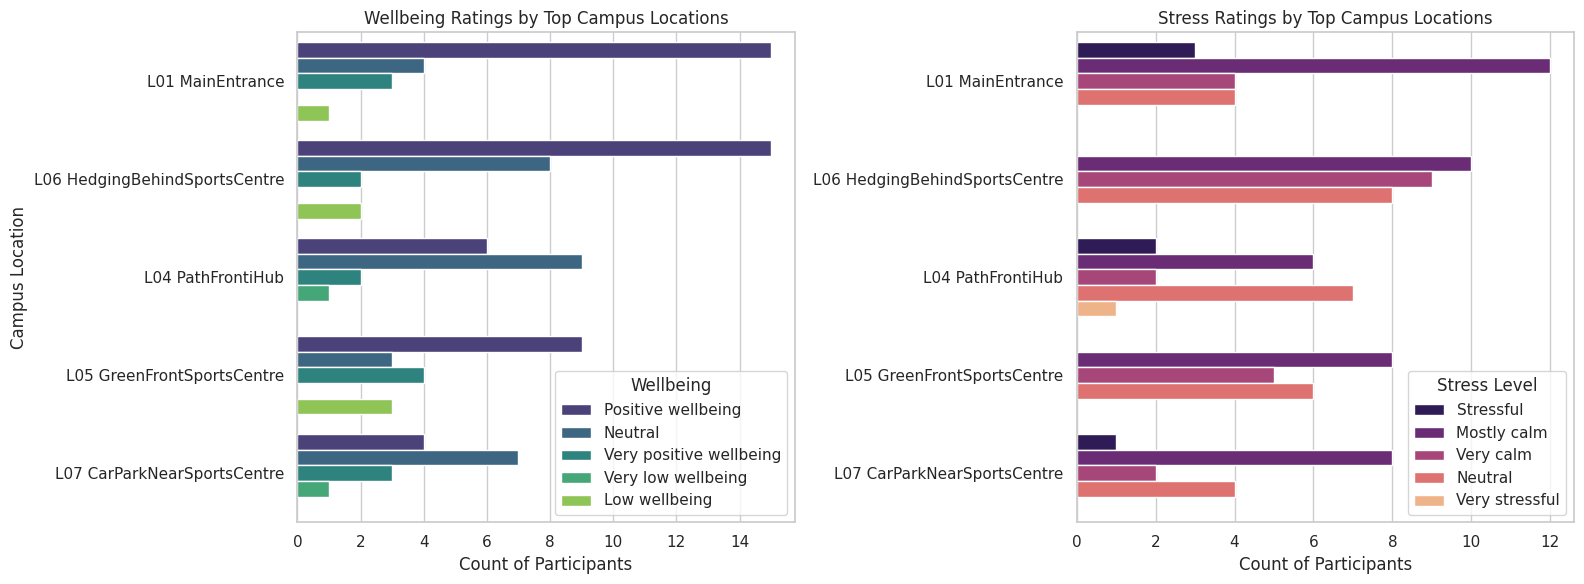

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter out missing values for these key comparison columns
vis_df = df.dropna(subset=['location', 'wellbeing_rating', 'stress_rating']).copy()

# Focus on the most visited campus locations
top_locations = vis_df['location'].value_counts().head(5).index
filtered_vis_df = vis_df[vis_df['location'].isin(top_locations)]

# Set style
sns.set_theme(style="whitegrid")

# Create a side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Wellbeing Ratings by Location
sns.countplot(
    data=filtered_vis_df,
    y='location',
    hue='wellbeing_rating',
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Wellbeing Ratings by Top Campus Locations')
axes[0].set_xlabel('Count of Participants')
axes[0].set_ylabel('Campus Location')
axes[0].legend(title='Wellbeing')

# 2. Stress Ratings by Location
sns.countplot(
    data=filtered_vis_df,
    y='location',
    hue='stress_rating',
    palette='magma',
    ax=axes[1]
)
axes[1].set_title('Stress Ratings by Top Campus Locations')
axes[1].set_xlabel('Count of Participants')
axes[1].set_ylabel('')
axes[1].legend(title='Stress Level')

plt.tight_layout()
plt.show()

Here we can see a **Side-by-side Bar Chart** showing the distribution of Wellbeing and Stress ratings across the top locations in the dataset.

### Analyzing the Impact of Weather on Wellbeing and Stress Levels

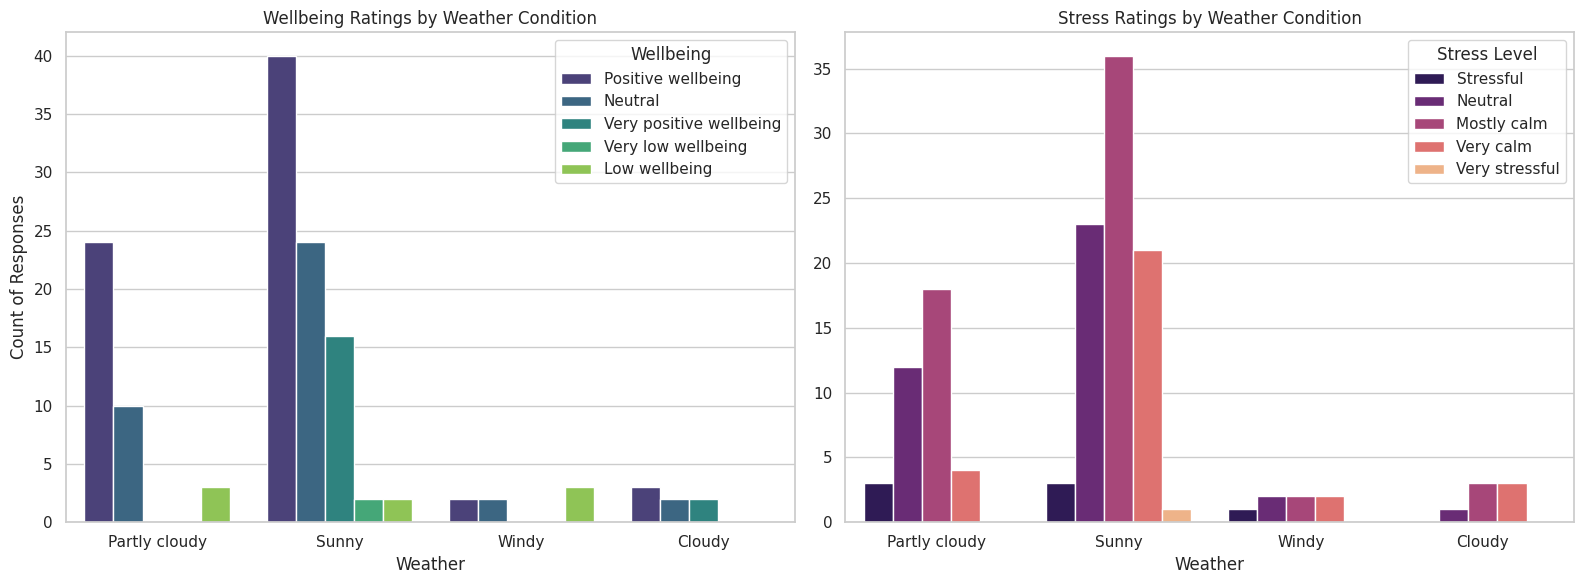

In [23]:
# Clean up casing for the weather column to group them correctly
weather_df = df.dropna(subset=['weather', 'wellbeing_rating', 'stress_rating']).copy()
weather_df['weather'] = weather_df['weather'].str.strip().str.capitalize()

# Create a side-by-side visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Weather vs. Wellbeing Rating
sns.countplot(
    data=weather_df,
    x='weather',
    hue='wellbeing_rating',
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Wellbeing Ratings by Weather Condition')
axes[0].set_xlabel('Weather')
axes[0].set_ylabel('Count of Responses')
axes[0].legend(title='Wellbeing')

# 2. Weather vs. Stress Rating
sns.countplot(
    data=weather_df,
    x='weather',
    hue='stress_rating',
    palette='magma',
    ax=axes[1]
)
axes[1].set_title('Stress Ratings by Weather Condition')
axes[1].set_xlabel('Weather')
axes[1].set_ylabel('')
axes[1].legend(title='Stress Level')

plt.tight_layout()
plt.show()

In [24]:
# Let's look at the average temperature recorded for each weather type
# and see if there is an objective difference we can report.
weather_df['temperature_c'] = pd.to_numeric(weather_df['temperature_c'], errors='coerce')
temp_summary = weather_df.groupby('weather')['temperature_c'].mean().reset_index()
print("Average Temperature (C) by Weather Condition:")
display(temp_summary)

Average Temperature (C) by Weather Condition:


,weather,temperature_c
0,Cloudy,15.200000
1,Partly cloudy,16.514286
2,Sunny,16.908451
3,Windy,11.750000


### Summary of Weather Comparison Insights

Based on the analysis of the graphs and temperature averages, we can draw the following conclusions:
1. **The Temperature Gap**: Windy weather is the coldest condition in our dataset, averaging **11.75°C**, which is over **5°C colder** than sunny days (averaging **16.91°C**).
2. **The Mood-Weather Connection**:
   * **Sunny** weather strongly correlates with high **Positive** and **Very positive** wellbeing, alongside **Calm** stress ratings.
   * **Partly cloudy** weather acts very similarly to sunny weather, showing that full sunshine isn't required to feel relaxed on a walk.
   * **Windy** and **cold weather** conditions show a visible shift toward **Low wellbeing** ratings, highlighting how physical discomfort from wind and lower temperatures directly influences participants' environmental experiences.